# 08 Topic modelling (bad reviews)

## Loading libraries and data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

os.makedirs("results/figures", exist_ok=True)
SEED = 42
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "savefig.dpi": 200})
LIKED_COL, DISLIKED_COL = "#eb6834", "#2a78d6"
CONTROLS = "C(rating) + log_popularity + log_age + verified"
FEATURES = {"reasons_pct": "Reasons", "mentions_pct": "Mentions of others", "certainty": "Certainty",
            "negation_pct": "Negation", "i_pct": "First-person I",
            "pos_emotion_clean_pct": "Positive emotion", "neg_emotion_clean_pct": "Negative emotion",
            "anger_clean_pct": "Anger", "sadness_clean_pct": "Sadness", "money_clean_pct": "Money"}
KEY = ["parent_asin", "user_id"]

df = pd.read_parquet("data/processed/features.parquet")
data = df[(df["rating"] <= 2) & (df["dissent_neg"] | df["agree_neg"])].copy()
data["well_liked"] = data["dissent_neg"].astype(int)
data["log_popularity"] = np.log(data["product_n_reviews"])
data["log_age"] = np.log1p(data["age_days"])
data["verified"] = data["verified_purchase"].astype(int)
data["text_clean"] = data["text_clean"].fillna("")
data = data.reset_index(drop=True)

display(pd.DataFrame({"reviews": data["well_liked"].value_counts()})
        .rename(index={1: "well-liked", 0: "disliked"}))
print("Reviews for topic modelling:", len(data))

,reviews
well_liked,
well-liked,16816
disliked,2881


Reviews for topic modelling: 19697


## Preprocessing for topics

In [2]:
vectorizer = CountVectorizer(lowercase=True, stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
                             min_df=20, max_df=0.30)
X = vectorizer.fit_transform(data["text_clean"])
vocab = vectorizer.get_feature_names_out()
print("Document-term matrix:", X.shape[0], "reviews x", X.shape[1], "words")

Document-term matrix: 19697 reviews x 2542 words


## Choosing the number of topics

,NPMI_coherence
topics,
5,0.0597
8,0.0571
10,0.0863
12,0.0728
15,0.0899
20,0.0465


Selected number of topics: 15


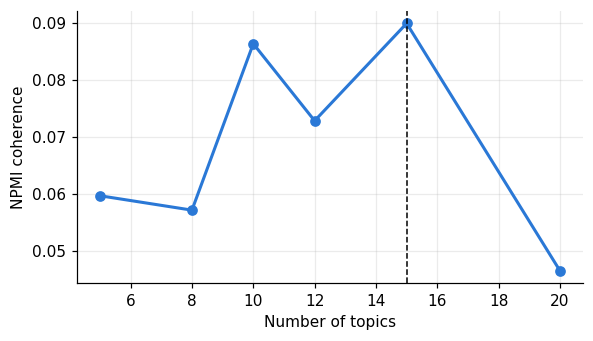

In [3]:
def npmi_coherence(model, Xbin, top_n=10):
    n_docs = Xbin.shape[0]
    scores = []
    for topic in model.components_:
        top = np.argsort(topic)[::-1][:top_n]
        sub = Xbin[:, top]
        p = np.asarray(sub.sum(axis=0)).ravel() / n_docs
        joint = (sub.T @ sub).toarray() / n_docs
        vals = []
        for i in range(top_n):
            for j in range(i + 1, top_n):
                pij = joint[i, j]
                vals.append(-1.0 if pij == 0 else np.log(pij / (p[i] * p[j])) / -np.log(pij))
        scores.append(np.mean(vals))
    return float(np.mean(scores))

def fit_lda(Xmat, k):
    return LatentDirichletAllocation(n_components=k, learning_method="online", batch_size=2048,
                                     max_iter=10, random_state=SEED, n_jobs=-1).fit(Xmat)

X_bin = (X > 0).astype(np.float32).tocsc()
K_GRID = [5, 8, 10, 12, 15, 20]
coherence = pd.DataFrame([{"topics": k, "NPMI_coherence": npmi_coherence(fit_lda(X, k), X_bin)} for k in K_GRID])
coherence.to_csv("results/topics_coherence_bad_reviews.csv", index=False)
BEST_K = int(coherence.sort_values(["NPMI_coherence", "topics"], ascending=[False, True]).iloc[0]["topics"])
display(coherence.round(4).set_index("topics"))
print("Selected number of topics:", BEST_K)

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(coherence["topics"], coherence["NPMI_coherence"], marker="o", color=DISLIKED_COL, linewidth=2)
ax.axvline(BEST_K, color="black", linewidth=1, linestyle="--")
ax.set_xlabel("Number of topics")
ax.set_ylabel("NPMI coherence")
fig.tight_layout()
fig.savefig("results/figures/fig_topics_coherence_bad_reviews.png")
plt.show()

## Final topic model

In [4]:
MODEL_FILE, TOPIC_FILE = "data/processed/lda_model_bad_reviews.joblib", "data/processed/feat_topics_bad_reviews.parquet"
if os.path.exists(MODEL_FILE) and os.path.exists(TOPIC_FILE):
    saved = joblib.load(MODEL_FILE)
    lda, vectorizer = saved["lda"], saved["vectorizer"]
    vocab = vectorizer.get_feature_names_out()
    topics = pd.read_parquet(TOPIC_FILE)
    print(MODEL_FILE, "and", TOPIC_FILE, "loaded (not refitted)")
else:
    lda = fit_lda(X, BEST_K)
    joblib.dump({"lda": lda, "vectorizer": vectorizer}, MODEL_FILE)
    theta = lda.transform(X)
    topics = data[KEY].copy()
    for t in range(theta.shape[1]):
        topics[f"topic_{t + 1}"] = theta[:, t]
    topics.to_parquet(TOPIC_FILE, index=False)
    print("Saved", MODEL_FILE, "and", TOPIC_FILE)

TOPIC_COLS = [c for c in topics.columns if c.startswith("topic_")]
top_words = pd.DataFrame({c: vocab[np.argsort(lda.components_[i])[::-1][:12]] for i, c in enumerate(TOPIC_COLS)}).T
top_words.columns = [f"w{i + 1}" for i in range(12)]
top_words.to_csv("results/topics_top_words_bad_reviews.csv")
display(top_words)

lda_model_bad_reviews.joblib and feat_topics_bad_reviews.parquet loaded (not refitted)


,w1,w2,w3,w4,w5,w6,w7,w8,w9,w10,w11,w12
topic_1,hair,shampoo,like,conditioner,just,did,dryer,work,use,dry,product,good
topic_2,money,waste,lashes,don,time,use,just,tried,glue,eyeliner,product,lash
topic_3,months,just,bought,use,working,worked,stopped,used,great,product,time,year
topic_4,nail,polish,nails,color,gel,like,product,colors,coat,just,light,use
topic_5,razor,shave,cut,blades,blade,shaver,shaving,drill,norelco,head,good,close
topic_6,small,fit,head,size,large,tight,clip,clips,que,big,wear,hold
topic_7,product,work,skin,didn,did,use,using,don,just,really,doesn,tried
topic_8,color,spray,water,brown,like,black,dark,white,bottle,blue,green,light
topic_9,brush,bristles,teeth,use,plastic,handle,like,hard,soft,good,head,short
topic_10,hair,product,use,hot,heat,used,stay,brows,does,like,recommend,setting


## Topic names

In [5]:
TOPIC_NAMES = {"topic_1": "Hair care", "topic_2": "Waste of money", "topic_3": "Stopped working over time",
               "topic_4": "Nail polish", "topic_5": "Razors and shavers", "topic_6": "Size and fit",
               "topic_7": "Did not work (skin)", "topic_8": "Colour (dye and spray)", "topic_9": "Toothbrushes",
               "topic_10": "Heat styling", "topic_11": "Delivery and returns", "topic_12": "Smell and scent",
               "topic_13": "Look and quality (wigs)", "topic_14": "Short use (feet, eyebrows)",
               "topic_15": "Brushes falling apart"}
display(pd.DataFrame({"topic name": [TOPIC_NAMES[c] for c in TOPIC_COLS],
                      "top words": [", ".join(top_words.loc[c, ["w1", "w2", "w3"]]) for c in TOPIC_COLS]}, index=TOPIC_COLS))

,topic name,top words
topic_1,Hair care,"hair, shampoo, like"
topic_2,Waste of money,"money, waste, lashes"
topic_3,Stopped working over time,"months, just, bought"
topic_4,Nail polish,"nail, polish, nails"
topic_5,Razors and shavers,"razor, shave, cut"
topic_6,Size and fit,"small, fit, head"
topic_7,Did not work (skin),"product, work, skin"
topic_8,Colour (dye and spray),"color, spray, water"
topic_9,Toothbrushes,"brush, bristles, teeth"
topic_10,Heat styling,"hair, product, use"


## Topic differences between the two groups

,share_well_liked_%,share_disliked_%,difference_pp,ci_low_pp,ci_high_pp,p,p_holm,significant
topic,,,,,,,,
Hair care,8.456,5.085,3.232,2.115,4.350,0.000,0.000,True
Waste of money,6.419,17.744,-10.911,-14.961,-6.861,0.000,0.000,True
Stopped working over time,7.261,6.657,0.202,-1.329,1.733,0.796,1.000,False
Nail polish,5.286,8.272,-2.937,-5.247,-0.628,0.013,0.127,False
Razors and shavers,3.072,2.843,-0.017,-0.862,0.827,0.968,1.000,False
Size and fit,4.334,4.050,0.463,-0.197,1.122,0.169,1.000,False
Did not work (skin),7.601,10.689,-4.069,-5.860,-2.277,0.000,0.000,True
Colour (dye and spray),3.879,3.260,0.573,-0.006,1.151,0.052,0.419,False
Toothbrushes,5.353,3.909,0.806,0.078,1.534,0.030,0.271,False


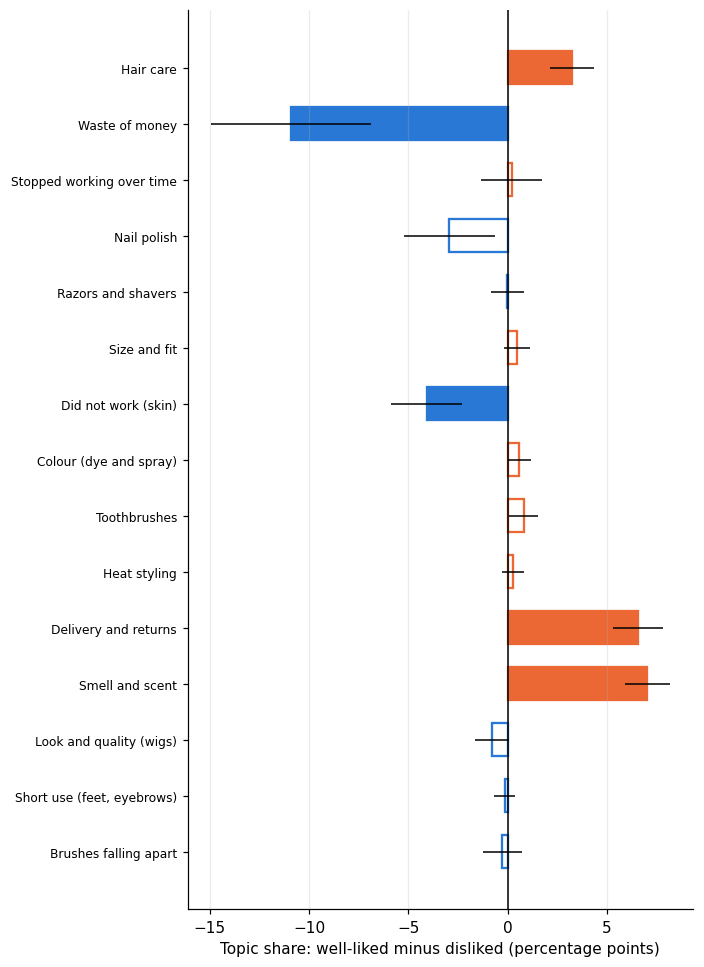

In [6]:
data = data.merge(topics, on=KEY, how="left", validate="one_to_one")
assert data[TOPIC_COLS].notna().all().all(), "Some reviews have no topic shares"

def cluster(d):
    return {"groups": pd.factorize(d["parent_asin"])[0]}

rows = []
for c in TOPIC_COLS:
    m = smf.ols(f"{c} ~ well_liked + {CONTROLS}", data=data).fit(cov_type="cluster", cov_kwds=cluster(data))
    rows.append({"topic": TOPIC_NAMES[c],
                 "share_well_liked_%": data.loc[data["well_liked"] == 1, c].mean() * 100,
                 "share_disliked_%": data.loc[data["well_liked"] == 0, c].mean() * 100,
                 "difference_pp": m.params["well_liked"] * 100,
                 "ci_low_pp": m.conf_int().loc["well_liked", 0] * 100,
                 "ci_high_pp": m.conf_int().loc["well_liked", 1] * 100,
                 "p": m.pvalues["well_liked"]})
topic_diff = pd.DataFrame(rows)
topic_diff["p_holm"] = multipletests(topic_diff["p"], method="holm")[1]
topic_diff["significant"] = topic_diff["p_holm"] < 0.05
topic_diff.to_csv("results/topics_differences_bad_reviews.csv", index=False)
display(topic_diff.round(3).set_index("topic"))

t = topic_diff.iloc[::-1]
y = np.arange(len(t))
colours = [LIKED_COL if v > 0 else DISLIKED_COL for v in t["difference_pp"]]
fig, ax = plt.subplots(figsize=(6.5, 0.5 * len(t) + 1.4))
ax.barh(y, t["difference_pp"], color=[c if s else "white" for c, s in zip(colours, t["significant"])],
        edgecolor=colours, linewidth=1.5, height=0.6)
ax.hlines(y, t["ci_low_pp"], t["ci_high_pp"], color="black", linewidth=1)
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(y, t["topic"], fontsize=8)
ax.set_xlabel("Topic share: well-liked minus disliked (percentage points)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("results/figures/fig_topics_bad_reviews.png")
plt.show()

## Robustness with topic controls

In [7]:
TOPIC_CONTROLS = " + ".join(TOPIC_COLS[:-1])

def pooled_sd(a, b):
    na, nb = len(a), len(b)
    return np.sqrt(((na - 1) * a.var() + (nb - 1) * b.var()) / (na + nb - 2))

rows = []
for col, name in FEATURES.items():
    s = data.dropna(subset=[col])
    sd = pooled_sd(s.loc[s["well_liked"] == 1, col], s.loc[s["well_liked"] == 0, col])
    for label, formula in [("main", f"{col} ~ well_liked + {CONTROLS}"),
                           ("with topics", f"{col} ~ well_liked + {CONTROLS} + {TOPIC_CONTROLS}"),
                           ("same main topic", f"{col} ~ well_liked + {CONTROLS} + C(main_topic)")]:
        if label == "same main topic":
            s = s.assign(main_topic=s[TOPIC_COLS].idxmax(axis=1))
        m = smf.ols(formula, data=s).fit(cov_type="cluster", cov_kwds=cluster(s))
        rows.append({"feature": name, "model": label, "d": m.params["well_liked"] / sd, "p": m.pvalues["well_liked"]})
rob = pd.DataFrame(rows)
rob["p_holm"] = rob.groupby("model")["p"].transform(lambda p: multipletests(p, method="holm")[1])
rob["significant"] = rob["p_holm"] < 0.05
rob.to_csv("results/topics_robustness_bad_reviews.csv", index=False)
display(rob.pivot(index="feature", columns="model", values=["d", "significant"])
        .reindex(list(FEATURES.values())).round(3))

d                             significant  \
model                   main same main topic with topics        main   
feature                                                                
Reasons             0.030026         0.01603    0.012111       False   
Mentions of others -0.019312       -0.002813    0.008437       False   
Certainty          -0.007842       -0.014079   -0.010834       False   
Negation           -0.239536       -0.187236    -0.16136        True   
First-person I      0.130856        0.117093    0.118091        True   
Positive emotion    0.026333         0.05062    0.074679       False   
Negative emotion   -0.057183       -0.023297    0.001568       False   
Anger              -0.121705       -0.035086    0.030936        True   
Sadness             0.054416        0.049431    0.046758       False   
Money               -0.08611       -0.000401    0.066772        True   

                                                
model              same main topic with topics  
feature                                         
Reasons                      False       False  
Mentions of others           False       False  
Certainty                    False       False  
Negation                      True        True  
First-person I                True        True  
Positive emotion             False       False  
Negative emotion             False       False  
Anger                        False       False  
Sadness                      False       False  
Money                        False       False

## Robustness inside each topic

In [8]:
data["main_topic"] = data[TOPIC_COLS].idxmax(axis=1)
display(pd.crosstab(data["main_topic"].map(TOPIC_NAMES), data["well_liked"].map({1: "well-liked", 0: "disliked"})))

MIN_N = 50
rows = []
for t in TOPIC_COLS:
    sub = data[data["main_topic"] == t]
    if min(int(sub["well_liked"].sum()), int((sub["well_liked"] == 0).sum())) < MIN_N:
        continue
    for col, name in FEATURES.items():
        s = sub.dropna(subset=[col])
        sd = pooled_sd(s.loc[s["well_liked"] == 1, col], s.loc[s["well_liked"] == 0, col])
        if not sd > 0:
            continue
        m = smf.ols(f"{col} ~ well_liked + {CONTROLS}", data=s).fit(cov_type="cluster", cov_kwds=cluster(s))
        rows.append({"product_type": TOPIC_NAMES[t], "feature": name, "d": m.params["well_liked"] / sd,
                     "p": m.pvalues["well_liked"]})
within = pd.DataFrame(rows)
within["p_holm"] = multipletests(within["p"], method="holm")[1]
within["significant"] = within["p_holm"] < 0.05
within.to_csv("results/topics_within_type_bad_reviews.csv", index=False)

main_d = rob[rob["model"] == "main"].set_index("feature")["d"]
summary = within.assign(same=np.sign(within["d"]) == np.sign(within["feature"].map(main_d))) \
    .groupby("feature", sort=False)[["same", "significant"]].apply(lambda g: pd.Series({"types_tested": len(g),
                                                               "same_direction": int(g["same"].sum()),
                                                               "same_direction_and_significant": int((g["same"] & g["significant"]).sum())}))
display(summary.reindex(list(FEATURES.values())))

well_liked,disliked,well-liked
main_topic,,
Brushes falling apart,144,792
Colour (dye and spray),52,416
Delivery and returns,322,2840
Did not work (skin),332,1325
Hair care,155,1586
Heat styling,69,450
Look and quality (wigs),292,1457
Nail polish,258,890
Razors and shavers,67,419


,types_tested,same_direction,same_direction_and_significant
feature,,,
Reasons,15,9,0
Mentions of others,15,6,0
Certainty,15,7,0
Negation,15,13,3
First-person I,15,13,0
Positive emotion,15,9,0
Negative emotion,15,10,0
Anger,15,9,0
Sadness,15,9,0
